## Agentic AI for Enrichment: Preliminary Investigation (Local LLM) - Qwen 3.5

This notebook focus on the preliminary investigation on the use of Agentic AI in the context of metadata enrichment.

Author: Boon Heng Chew <<s2831745@sms.ed.ac.uk>>

> Link to **Research Question:** Does agentic enrichment of extracted structural metadata improve cross language repository similarity ranking accuracy compared to unenriched metadata?

This notebook implements the **core agentic enrichment pipeline** using:
- `LangGraph` - ReAct-style agent graph (Thought -> Action -> Observation loop)
- `LM Studio` - local LLM server (Qwen) via OpenAI-compatible API
- `inspect4j` output - real Java repository metadata (java-jwt) as input

#### Experiment Agentic Workflow
- Load inspect4j JSON output from the software project / git repository `java-jwt`
- Flatten into a list of method records
- Run a LangGraph ReAct agent that:
  1. Detects gaps (methods with missing documentation)
  2. Enriches each gap with a generated docstring via `enrich_docstring` tool
  3. Tags each field with provenance: `tool | agent_backfill | missing`
  4. Emits `finish` when gaps are exhausted (max-step cap = 20)
- Compare before/after metadata quality

In [1]:
from platform import python_version

# show environment
print(f"Python environment: {python_version()}")

Python environment: 3.12.11


#### 0. Pre-Setup

Before continuing, ensure LM Studio is install and the model is already downloaded and loaded into the studio. Refer to https://lmstudio.ai/docs/app/basics

The original experiment is conducted with LM Studio v4.6 and `Qwen3.5-27B-Claude-4.6-Opus-Reasoning-Distilled`, a reasoning model fine-tuned on top of the Qwen3.5 architecture to leverage on the state-of-the-art Chain-of-Thought (CoT) distillation primarily sourced from Claude-4.6 Opus interactions. 

In [2]:
import json
import os
import random
from pathlib import Path
from typing import Annotated, Any, TypedDict

import requests

# Verify LM Studio server is reachable before proceeding
LM_STUDIO_BASE_URL = "http://localhost:1234/v1"

try:
    resp = requests.get(f"{LM_STUDIO_BASE_URL}/models", timeout=3)
    models = resp.json().get("data", [])
    if models:
        print(f'[OK] LM Studio server reachable at {LM_STUDIO_BASE_URL}')
        print(f'  Loaded models: {[m["id"] for m in models]}')
    else:
        print("[NOTE] LM Studio reachable but no model loaded -- load a Qwen model first")
except Exception as e:
    raise RuntimeError(
        f"LM Studio server not reachable at {LM_STUDIO_BASE_URL}\n"
        "Start LM Studio, load a Qwen model, and enable the local server (port 1234)."
    ) from e

[OK] LM Studio server reachable at http://localhost:1234/v1
  Loaded models: ['qwen3.5-27b-claude-4.6-opus-reasoning-distilled', 'gemma-4-31b-it', 'minimax-m2.5-jang_3l', 'minimax-m2.5', 'nvidia/nemotron-3-super', 'minimax-m2.5-jang_3l-crack', 'qwen/qwen3.5-35b-a3b', 'google/gemma-4-26b-a4b', 'qwen/qwen3-coder-30b', 'zai-org/glm-4.7-flash', 'openai/gpt-oss-20b', 'glm-4.5-air-mlx', 'text-embedding-nomic-embed-text-v1.5']


In [4]:
# LM Studio configuration
# LLM_MODEL must match the model ID shown in LM Studio (copy from the server tab)
LLM_MODEL = "qwen3.5-27b-claude-4.6-opus-reasoning-distilled"   # <- update to match what you have loaded

# Workflow configuration
INSPECT4J_OUTPUT = Path('data/sample_inspect4j_directory_info.json')
""" a sample output from inspect4j """

MAX_ENRICHMENT_STEPS = 50
""" Control the max step to take to avoid infinite loop when agent can't reach exit condition"""

MAX_RETRY_ENRICHMENT = 2
""" Max Reflexion-style retries per method when validation fails"""

VALIDATION_CONFIDENCE_THRESHOLD = 0.6
""" Confidence threshold for validation. Lower for local models (0.6 vs 0.7 for frontier) since Qwen scores lower. """

SAMPLE_SIZE_EACH = 5
""" The number of methods to enrich on. """

RANDOM_SEED = 42

print(f'Input:      {INSPECT4J_OUTPUT}')
print(f'Model:      {LLM_MODEL}')
print(f'Backend:    LM Studio ({LM_STUDIO_BASE_URL})')
print(f'Max steps:  {MAX_ENRICHMENT_STEPS}')
print(f'Max retries:{MAX_RETRY_ENRICHMENT}')
print(f'Confidence: {VALIDATION_CONFIDENCE_THRESHOLD}')

Input:      data/sample_inspect4j_directory_info.json
Model:      qwen3.5-27b-claude-4.6-opus-reasoning-distilled
Backend:    LM Studio (http://localhost:1234/v1)
Max steps:  50
Max retries:2
Confidence: 0.6


#### 2. Load & Flatten inspect4j Output

In [5]:
def load_inspect4j(path: Path) -> list[dict[str, Any]]:
    """Flatten nested inspect4j directory_info.json into a list of method records."""
    with path.open(encoding='utf-8') as f:
        data = json.load(f)
    methods = []
    for _pkg_key, files in data.items():
        for file_info in files:
            file_path = file_info.get('file', {}).get('path', '')
            pkg_name = file_info.get('package', {}).get('name', '')
            deps = file_info.get('dependencies', [])
            for cls_name, cls_data in file_info.get('classes', {}).items():
                for method_name, method_data in cls_data.get('methods', {}).items():
                    doc = method_data.get('doc', {}) or {}
                    description = doc.get('description', '').strip()
                    methods.append({
                        'id': f'{pkg_name}.{cls_name}.{method_name}',
                        'file': file_path,
                        'package': pkg_name,
                        'class': cls_name,
                        'method': method_name,
                        'modifiers': method_data.get('modifiers', []),
                        'parameters': method_data.get('parameters', []),
                        'return_type': method_data.get('return_type'),
                        'annotations': method_data.get('annotations', []),
                        'calls': method_data.get('calls', []),
                        'doc': {'description': description, 'tags': doc.get('comment_tags', {})},
                        'class_deps': [d.get('from_module') for d in deps],
                        'provenance': {'doc': 'tool' if description else 'missing'},
                    })
    return methods


all_methods = load_inspect4j(INSPECT4J_OUTPUT)
methods_with_doc = [m for m in all_methods if m['provenance']['doc'] == 'tool']
methods_missing_doc = [m for m in all_methods if m['provenance']['doc'] == 'missing']

print(f'Total methods:         {len(all_methods)}')
print(f'With documentation:    {len(methods_with_doc)} ({len(methods_with_doc)/len(all_methods)*100:.1f}%)')
print(f'Missing documentation: {len(methods_missing_doc)} ({len(methods_missing_doc)/len(all_methods)*100:.1f}%)')

Total methods:         924
With documentation:    55 (6.0%)
Missing documentation: 869 (94.0%)


In [6]:
random.seed(RANDOM_SEED)
sample_with_doc = random.sample(methods_with_doc, min(SAMPLE_SIZE_EACH, len(methods_with_doc)))
sample_missing_doc = random.sample(methods_missing_doc, min(SAMPLE_SIZE_EACH, len(methods_missing_doc)))
experiment_sample = sample_with_doc + sample_missing_doc

print(f'Experiment sample: {len(experiment_sample)} methods')
print(f'  {len(sample_with_doc)} with existing docs (control group)')
print(f'  {len(sample_missing_doc)} missing docs (treatment - to enrich)')
print()
m = sample_with_doc[0]
print('Example (control):')
print(f'  {m["id"]}')
print(f'  Doc Description: {m["doc"]["description"][:120]}')
print()
m = sample_missing_doc[0]
params_str = ", ".join(f'{p["type"]} {p["name"]}' for p in m["parameters"])
print('Example (treatment):')
print(f'  {m["id"]}')
print(f'  Signature: {m["method"]}({params_str}) -> {m["return_type"]}')
print(f'  Doc Description: <none>')

Experiment sample: 10 methods
  5 with existing docs (control group)
  5 missing docs (treatment - to enrich)

Example (control):
  com.auth0.jwt.algorithms.CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])
  Doc Description: Verify signature for JWT header and payload.

Example (treatment):
  com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt
  Signature: shouldGetIssuedAt() -> None
  Doc Description: <none>


## 3. LangGraph ReAct Enrichment Agent

The agent follows the **ReAct pattern** (Yao et al., 2022) with a three-layer quality mechanism:

```
START -> agent (Thought) -> tools (Action+Observation) -> agent -> ... -> END

  Step 1: detect_gaps         -- analyse all methods, produce structured gap report

  Step 2: enrich_docstring    -- generate docstring with:
            * component-type-specific prompt (constructor / test / static / instance)  [DocAgent]
            * dependency context: already-enriched docstrings of called methods        [DocAgent + Structured metadata as context]
            * optional feedback from failed validation for Reflexion retry             [Reflexion]

  Step 3: validate_enrichment -- three-dimensional check:
            Dim 1 Helpfulness:   LLM-as-judge coherence + hallucination check          [CRAG]
            Dim 2 Truthfulness:  entity cross-reference against _method_registry       [DocAgent + Structured metadata as context]
            Dim 3 Reflexion gate: retry decision with verbal feedback                  [Self-RAG + Reflexion]
            +-- PASS (confidence >= 0.6, entities verified) -> provenance: agent_enriched
            +-- FAIL + retries remaining -> retry_recommended=True
            |     -> enrich_docstring(method_id, feedback=retry_feedback)  [Reflexion loop]
            \-- FAIL + retries exhausted -> provenance: agent_backfill_unvalidated

  Step 4: finish              -- summarise what was done
```

### Tools registered

| Tool | Purpose | Theory |
|------|---------|--------|
| `detect_gaps` | Structured gap analysis -- missing doc, weak doc, javalang parse failures | ReAct |
| `enrich_docstring` | Type-specific prompt + dependency context + Reflexion feedback support | DocAgent, Reflexion |
| `validate_enrichment` | Helpfulness (LLM-judge) + Truthfulness (entity check) + Reflexion gate | CRAG, Reflexion, DocAgent |
| `finish` | Signal enrichment complete | -- |

In [7]:
import re

from langchain_core.messages import AnyMessage, HumanMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode


def _make_llm() -> ChatOpenAI:
    """Create a ChatOpenAI client pointing at the local LM Studio server.

    LM Studio exposes an OpenAI-compatible API -- no real API key needed.
    reasoning_effort and use_responses_api are OpenAI-specific and must be omitted.
    """
    return ChatOpenAI(
        model=LLM_MODEL,
        base_url=LM_STUDIO_BASE_URL,
        api_key="lm-studio",   # dummy value as LM Studio does not validate the key
        temperature=0,
    )


class EnrichmentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    methods_to_enrich: list[dict]
    enriched: list[dict]
    step_count: int
    finished: bool


# --- Registries ---
# Ground-truth method dicts: tools look up by ID, never trust LLM-reconstructed dicts
_method_registry: dict[str, dict] = {}
# Enriched registry: written by enrich_docstring, updated by validate_enrichment
_enriched_registry: dict[str, dict] = {}
# Retry counter: tracks Reflexion retry attempts per method
_retry_registry: dict[str, int] = {}

# --- Constants ---
_JAVALANG_UNPARSEABLE_ANNOTATIONS = {
    'RestController', 'Controller', 'Service', 'Repository',
    'Component', 'SpringBootApplication', 'Configuration',
    'Data', 'Builder', 'Getter', 'Setter',
}
_WEAK_DOC_MAX_CHARS = 30
_VALIDATION_CONFIDENCE_THRESHOLD = VALIDATION_CONFIDENCE_THRESHOLD

# Java standard types excluded from truthfulness check (too common to flag)
_JAVA_BUILTINS = {
    'String', 'Integer', 'Double', 'Float', 'Long', 'Boolean', 'Byte', 'Short',
    'Object', 'Class', 'Void', 'Number', 'Math', 'System',
    'List', 'Map', 'Set', 'Collection', 'Iterator', 'Optional',
    'Exception', 'RuntimeException', 'IllegalArgumentException',
    'IllegalStateException', 'NullPointerException', 'UnsupportedOperationException',
    # JWT project-level types that appear ubiquitously (too broad to flag)
    'JWT', 'Claim', 'Algorithm', 'DecodedJWT', 'Payload', 'Header',
    'JsonNode', 'ObjectMapper', 'Date', 'Instant',
}


# --- Helpers ---

def _extract_text(content: str | list) -> str:
    """Extract plain text from LLM response (Chat Completions str or Responses API list)."""
    if isinstance(content, str):
        return content.strip()
    return ''.join(
        block.get('text', '') if isinstance(block, dict) else str(block)
        for block in content
    ).strip()


def _classify_gaps(method: dict) -> list[str]:
    """Classify what metadata gaps exist in a single method record."""
    gaps = []
    description = method.get('doc', {}).get('description', '').strip()
    if not description:
        gaps.append('missing_docstring')
    elif len(description) < _WEAK_DOC_MAX_CHARS:
        gaps.append('weak_docstring')
    return_type = method.get('return_type')
    is_constructor = method['method'] == method['class']
    if not is_constructor and return_type is None:
        gaps.append('missing_return_type')
    annotation_names = {a.get('name', '') for a in method.get('annotations', [])}
    unparseable = annotation_names & _JAVALANG_UNPARSEABLE_ANNOTATIONS
    if unparseable:
        gaps.append(f'unparsed_construct:{",".join(sorted(unparseable))}')
    return gaps


def _detect_method_type(method: dict) -> str:
    """Classify method type for component-type-specific prompting (DocAgent Writer templates)."""
    method_name = method['method']
    class_name = method['class']
    modifiers = method.get('modifiers', [])
    annotation_names = {a.get('name', '') for a in method.get('annotations', [])}
    _test_annotations = {'Test', 'ParameterizedTest', 'BeforeEach', 'AfterEach', 'BeforeAll', 'AfterAll'}
    if method_name == class_name:
        return 'constructor'
    if annotation_names & _test_annotations or method_name.startswith(('test', 'should')):
        return 'test'
    if 'static' in modifiers:
        return 'static'
    return 'instance'


def _build_dependency_context(method: dict) -> str:
    """Build context from already-enriched docstrings of called methods.

    Implements DocAgent's 'Dependencies First' principle: when documenting method A
    that calls method B, include B's already-enriched docstring as grounding context.
    This reduces hallucination and improves specificity.
    """
    lines = []
    for call_name in method.get('calls', [])[:5]:
        call_short = call_name.split('.')[-1]
        for mid, enriched in _enriched_registry.items():
            mid_method = mid.split('.')[-1].split('(')[0]
            if mid_method == call_short:
                doc = enriched.get('doc', {}).get('description', '').strip()
                if doc:
                    lines.append(f'  - {call_short}: {doc[:100]}')
                break
    return '\n'.join(lines)


def _extract_code_entities(text: str) -> set[str]:
    """Extract code entity references from a docstring for truthfulness checking."""
    entities: set[str] = set()
    # Javadoc cross-references: {@link Foo}, {@code bar}
    entities.update(re.findall(r'\{@(?:link|code)\s+(\w+)', text))
    # UpperCamelCase class names
    entities.update(re.findall(r'\b([A-Z][a-z]+(?:[A-Z][a-z]*)+)\b', text))
    # Backtick code references: `foo`
    entities.update(re.findall(r'`(\w+)`', text))
    return entities


def _check_truthfulness(description: str) -> list[str]:
    """Verify code entities in the docstring exist in the method registry.

    DocAgent's truthfulness dimension: cross-reference mentioned entities against
    the AST-derived registry as ground truth to detect hallucinated references.
    """
    known: set[str] = set()
    for mid in _method_registry:
        known.update(mid.split('.'))
    known |= _JAVA_BUILTINS
    mentioned = _extract_code_entities(description)
    issues = [
        f'unverified entity: {e}'
        for e in sorted(mentioned)
        if len(e) >= 5 and e not in known
    ]
    return issues[:3]


def _build_enrich_prompt(
    method: dict,
    method_type: str,
    dependency_context: str,
    feedback: str,
) -> str:
    """Build a component-type-specific enrichment prompt (DocAgent Writer templates)."""
    params_str = ', '.join(f"{p['type']} {p['name']}" for p in method.get('parameters', []))
    return_type = method.get('return_type') or 'void'
    annotations = [a.get('name') for a in method.get('annotations', [])]
    modifiers = ' '.join(method.get('modifiers', []))
    _type_guidance = {
        'constructor': (
            'This is a CONSTRUCTOR. Describe: what state it initialises, '
            'what each parameter represents, and any validation or exception it may throw.'
        ),
        'test': (
            'This is a TEST METHOD. Describe: what behaviour or condition it verifies, '
            'what the expected outcome is, and what scenario is implied by the name.'
        ),
        'static': (
            'This is a STATIC UTILITY or FACTORY METHOD. Describe: what it computes or '
            'creates, input constraints, and what the return value represents.'
        ),
        'instance': (
            'This is an INSTANCE METHOD. Describe: the operation performed on object state, '
            'what each parameter controls, and what the return value represents.'
        ),
    }
    prompt = (
        'You are a Java documentation expert. Generate a concise Javadoc-style description '
        '(1-2 sentences, be concise) for the following Java method.\n\n'
        f'{_type_guidance[method_type]}\n\n'
        f"Class: {method['class']} (package: {method['package']})\n"
        f"Method signature: {modifiers} {return_type} {method['method']}({params_str})\n"
        f"Annotations: {annotations if annotations else 'none'}\n"
    )
    if dependency_context:
        prompt += (
            '\nDocumentation of called methods -- use for context, do not copy verbatim:\n'
            f'{dependency_context}\n'
        )
    if feedback:
        prompt += (
            f'\nPrevious attempt was rejected. Issues identified:\n  {feedback}\n'
            'Please address these issues specifically in your revised description.\n'
        )
    prompt += '\nWrite ONLY the description text (no @param/@return tags). Be concise and accurate.'
    return prompt


# --- Tools ---

@tool
def detect_gaps(method_ids: list[str]) -> str:
    """Analyse a set of methods and produce a structured gap report.

    Diagnoses each method for:
    - missing_docstring: no documentation at all
    - weak_docstring: description exists but too short (<30 chars)
    - missing_return_type: null return type -- likely a javalang parse failure on Java 9+ generics
    - unparsed_construct:<name>: Spring/Lombok annotation javalang cannot resolve

    Args:
        method_ids: List of method IDs to analyse (format: 'package.Class.method').
    """
    gap_report: dict[str, list[str]] = {}
    no_gaps = []
    already_enriched = []
    for mid in method_ids:
        method = _method_registry.get(mid)
        if method is None:
            gap_report[mid] = ['not_found_in_registry']
            continue
        # Check enriched registry first -- reflects current pipeline state
        _ep = _enriched_registry.get(mid, {}).get('provenance', {}).get('doc', '')
        if _ep in ('agent_enriched', 'agent_backfill_unvalidated'):
            already_enriched.append(mid)
            continue
        gaps = _classify_gaps(method)
        if gaps:
            gap_report[mid] = gaps
        else:
            no_gaps.append(mid)
    if not gap_report:
        if already_enriched:
            return (
                f'All gaps resolved. {len(already_enriched)} method(s) enriched and finalised, '
                f'{len(no_gaps)} had no gaps originally. Call finish now.'
            )
        return 'No gaps detected. All methods have complete metadata.'
    lines = [f'Gap analysis for {len(method_ids)} methods:\n']
    if already_enriched:
        lines.append(f'  [done] {len(already_enriched)} already enriched/finalised -- do NOT re-process.')
    by_type: dict[str, list[str]] = {}
    for mid, gaps in gap_report.items():
        for g in gaps:
            by_type.setdefault(g, []).append(mid)
    for gap_type, affected in sorted(by_type.items()):
        lines.append(f'  [{gap_type}] ({len(affected)} methods):')
        for mid in affected[:8]:
            lines.append(f'    - {mid}')
        if len(affected) > 8:
            lines.append(f'    ... and {len(affected) - 8} more')
    lines.append(f'\n  No gaps: {len(no_gaps)} methods with sufficient existing metadata.')
    lines.append(
        '\nNext steps:'
        '\n  1. Call enrich_docstring for each method with missing_docstring or weak_docstring.'
        '\n  2. After each enrichment, call validate_enrichment to check quality.'
        '\n  3. If validate_enrichment returns retry_recommended=true, call enrich_docstring'
        '\n     again with the retry_feedback value as the feedback argument (Reflexion retry).'
        '\n  4. Methods with missing_return_type or unparsed_construct are javalang limitations'
        '\n     -- record them but do not attempt docstring enrichment.'
        '\n  5. Call finish once all gaps are resolved.'
    )
    return '\n'.join(lines)


@tool
def enrich_docstring(method_id: str, feedback: str = '') -> dict:
    """Generate an English Javadoc description for a Java method.

    Uses component-type-specific prompting (constructor / test / static / instance) and
    includes already-enriched docstrings of called methods as dependency context, following
    DocAgent's 'Dependencies First' principle to reduce hallucination.

    When a previous validate_enrichment failed, pass its retry_feedback here to trigger
    a Reflexion-style retry with verbal reinforcement (P68).

    Args:
        method_id: The method ID in format 'package.Class.method'.
        feedback: Verbal feedback from a failed validation (leave empty on first attempt).
    """
    method = _method_registry.get(method_id)
    if method is None:
        return {'error': f'method_id "{method_id}" not found in registry'}
    # Guard: do not re-enrich a method already at final provenance (prevents Qwen looping)
    _cur = _enriched_registry.get(method_id, {})
    _cur_prov = _cur.get('provenance', {}).get('doc', '')
    if _cur_prov in ('agent_enriched', 'agent_backfill_unvalidated'):
        return {
            'info': f'SKIP: "{method_id}" already finalised ({_cur_prov}). Do NOT re-enrich. Move to the next undocumented method or call finish.',
            'provenance': _cur_prov,
        }
    method_type = _detect_method_type(method)
    dependency_context = _build_dependency_context(method)
    prompt = _build_enrich_prompt(method, method_type, dependency_context, feedback)
    response = _make_llm().invoke(prompt)
    generated_description = _extract_text(response.content)
    enriched = method.copy()
    enriched['doc'] = {'description': generated_description, 'tags': method.get('doc', {}).get('tags', {})}
    enriched['provenance'] = {**method.get('provenance', {}), 'doc': 'agent_backfill'}
    _enriched_registry[method_id] = enriched
    return enriched


@tool
def validate_enrichment(method_id: str) -> dict:
    """Validate the quality of a generated docstring using a three-dimensional check.

    Dim 1 Helpfulness:   LLM-as-judge coherence + hallucination check.
    Dim 2 Truthfulness:  code entities in the docstring are cross-referenced against
                         _method_registry to detect hallucinated references.
    Dim 3 Reflexion gate: if validation fails and retries remain, returns
                          retry_recommended=True with retry_feedback.

    Provenance outcomes:
      agent_enriched           -- passed all dimensions
      agent_backfill           -- failed but retry available; call enrich_docstring(feedback=...)
      agent_backfill_unvalidated -- failed, retries exhausted

    Args:
        method_id: The method ID to validate (must have been enriched first).
    """
    enriched = _enriched_registry.get(method_id)
    if enriched is None:
        return {'error': f'No enriched record for "{method_id}". Call enrich_docstring first.'}
    # Guard: do not re-validate a method already at final provenance (prevents Qwen looping)
    _vp = enriched.get('provenance', {}).get('doc', '')
    if _vp in ('agent_enriched', 'agent_backfill_unvalidated'):
        return {
            'info': f'SKIP: "{method_id}" already finalised ({_vp}). Do NOT re-validate. Move to the next undocumented method or call finish.',
            'method_id': method_id,
            'provenance': _vp,
        }
    method = _method_registry[method_id]
    description = enriched['doc']['description']
    params_str = ', '.join(f"{p['type']} {p['name']}" for p in method.get('parameters', []))
    return_type = method.get('return_type') or 'void'
    modifiers = ' '.join(method.get('modifiers', []))
    calls = method.get('calls', [])[:5]

    # Dim 1: Helpfulness -- LLM-as-judge
    validation_prompt = (
        'You are a code documentation quality reviewer. '
        'Assess the following generated Javadoc description against the method signature.\n\n'
        f"Method signature: {modifiers} {return_type} {method['method']}({params_str})\n"
        f"Class: {method['class']} (package: {method['package']})\n"
        f"Method calls: {calls if calls else 'none'}\n\n"
        f'Generated description:\n"{description}"\n\n'
        'Evaluate on three criteria:\n'
        '1. Accuracy: Does the description correctly describe what the method does?\n'
        '2. Hallucination: Does it mention parameters, types, or behaviours NOT present in the signature?\n'
        '3. Quality: Is it specific and useful, not just a restatement of the method name?\n\n'
        'Respond ONLY with valid JSON in this exact format (no markdown, no explanation):\n'
        '{"valid": true|false, "confidence": 0.0-1.0, "issues": ["issue1"]}'
    )
    response = _make_llm().invoke(validation_prompt)
    raw = _extract_text(response.content)
    try:
        clean = raw.strip().removeprefix('```json').removeprefix('```').removesuffix('```').strip()
        result = json.loads(clean)
        confidence = float(result.get('confidence', 0.0))
        llm_valid = result.get('valid', False)
        llm_issues = result.get('issues', [])
    except (json.JSONDecodeError, ValueError):
        llm_valid = False
        confidence = 0.0
        llm_issues = [f'validator_parse_error: {raw[:100]}']

    # Dim 2: Truthfulness (entity cross-reference)
    truth_issues = _check_truthfulness(description)
    if truth_issues:
        confidence = max(0.0, confidence - 0.1 * len(truth_issues))
    all_issues = llm_issues + truth_issues
    valid = llm_valid and confidence >= _VALIDATION_CONFIDENCE_THRESHOLD

    # Dim 3: Reflexion retry gate
    retries_used = _retry_registry.get(method_id, 0)
    retry_available = not valid and retries_used < MAX_RETRY_ENRICHMENT
    if valid:
        final_provenance = 'agent_enriched'
    elif retry_available:
        final_provenance = 'agent_backfill'  # remains mutable until retries exhausted or pass
        _retry_registry[method_id] = retries_used + 1
    else:
        final_provenance = 'agent_backfill_unvalidated'

    enriched['provenance']['doc'] = final_provenance
    _enriched_registry[method_id] = enriched

    out: dict = {
        'method_id': method_id,
        'valid': valid,
        'confidence': round(confidence, 3),
        'issues': all_issues,
        'truthfulness_issues': truth_issues,
        'provenance': final_provenance,
        'description_preview': description[:120],
    }
    if retry_available:
        feedback_str = '; '.join(all_issues) if all_issues else 'low confidence -- improve specificity'
        out['retry_recommended'] = True
        out['retry_feedback'] = feedback_str
        out['retries_remaining'] = MAX_RETRY_ENRICHMENT - _retry_registry[method_id]
        out['action'] = (
            f'Call enrich_docstring(method_id="{method_id}", feedback="{feedback_str}") '
            f'to retry with Reflexion verbal feedback.'
        )
    return out


@tool
def finish(summary: str) -> str:
    """Signal that enrichment is complete and provide a summary."""
    return f'ENRICHMENT COMPLETE: {summary}'


tools = [detect_gaps, enrich_docstring, validate_enrichment, finish]
print(f'[OK] {len(tools)} tools registered: {[t.name for t in tools]}')
print('  enrich_docstring:    component-type prompts + dependency context')
print('  validate_enrichment: helpfulness + truthfulness + Reflexion gate')

[OK] 4 tools registered: ['detect_gaps', 'enrich_docstring', 'validate_enrichment', 'finish']
  enrich_docstring:    component-type prompts + dependency context
  validate_enrichment: helpfulness + truthfulness + Reflexion gate


In [22]:
llm = _make_llm()
llm_with_tools = llm.bind_tools(tools)


def agent_node(state: EnrichmentState) -> dict:
    """Agent reasoning node -- LLM decides the next action."""
    response = llm_with_tools.invoke(state['messages'])
    return {'messages': [response]}


def should_continue(state: EnrichmentState) -> str:
    """Routing: continue ReAct loop or terminate.

    Three exit conditions (checked in priority order):
      1. Hard step cap  -- MAX_ENRICHMENT_STEPS reached (safety, model-agnostic)
      2. Semantic exit  -- all treatment methods have a final provenance in the enriched
                          registry (model-agnostic; does not require the model to call finish)
      3. Model exit     -- model called finish, or emitted no tool calls
    """
    # 1. Hard safety cap -- always respected regardless of model behaviour
    if state['step_count'] >= MAX_ENRICHMENT_STEPS:
        print(f'  [SAFETY] Max steps ({MAX_ENRICHMENT_STEPS}) reached -- terminating.')
        return END

    # 2. Semantic completion check -- exit as soon as all gaps are resolved
    treatment_ids = {
        m['id'] for m in state['methods_to_enrich']
        if m['provenance']['doc'] == 'missing'
    }
    if treatment_ids:
        _final = ('agent_enriched', 'agent_backfill_unvalidated')
        all_done = all(
            _enriched_registry.get(mid, {}).get('provenance', {}).get('doc') in _final
            for mid in treatment_ids
        )
        if all_done:
            print(f'  [AUTO-EXIT] All {len(treatment_ids)} treatment methods validated -- terminating.')
            return END

    # 3. Model-driven exit -- finish tool call or no tool calls
    last_message = state['messages'][-1]
    tool_calls = getattr(last_message, 'tool_calls', [])
    if not tool_calls:
        return END
    for tc in tool_calls:
        if tc['name'] == 'finish':
            return END
    return 'tools'


def increment_step(state: EnrichmentState) -> dict:
    """Increment the step counter after each tool execution."""
    new_count = state['step_count'] + 1
    print(f'  Step {new_count}: tool executed')
    return {'step_count': new_count}


tool_node = ToolNode(tools)
builder = StateGraph(EnrichmentState)
builder.add_node('agent', agent_node)
builder.add_node('tools', tool_node)
builder.add_node('step_counter', increment_step)
builder.add_edge(START, 'agent')
builder.add_conditional_edges('agent', should_continue, {'tools': 'tools', END: END})
builder.add_edge('tools', 'step_counter')
builder.add_edge('step_counter', 'agent')
graph = builder.compile()

print('[OK] LangGraph agent compiled (LM Studio / Qwen backend)')
print('  Graph: START -> agent -> [tools -> step_counter -> agent]* -> END')
print('  Exit:  step_cap | all_validated | finish | no_tool_calls')

[OK] LangGraph agent compiled (LM Studio / Qwen backend)
  Graph: START -> agent -> [tools -> step_counter -> agent]* -> END
  Exit:  step_cap | all_validated | finish | no_tool_calls


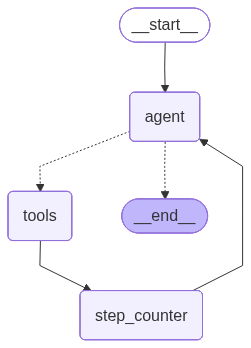

In [23]:
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f'Graph visualisation unavailable: {e}')

## 4. Run the Enrichment Agent

In [24]:
def build_prompt(methods: list[dict]) -> str:
    """Build the initial agent prompt.

    Passes ALL methods (with and without docs) so the agent must call detect_gaps
    first to discover which ones need enrichment -- proper ReAct analysis step.
    """
    lines = []
    for i, m in enumerate(methods):
        params = ', '.join(f"{p['type']} {p['name']}" for p in m.get('parameters', []))
        lines.append(f"  {i+1}. {m['id']}  ({m['class']}.{m['method']}({params}) -> {m['return_type'] or 'void'})")
    method_list = '\n'.join(lines)

    return (
        f'You are an agentic metadata enrichment system for the Java repository "java-jwt".\n\n'
        f'You have been given {len(methods)} method IDs from this repository. '
        f'Some methods already have documentation; others do not.\n\n'
        f'Your task:\n'
        f'  1. Call `detect_gaps` with ALL method IDs below to identify which methods need documentation.\n'
        f'  2. For each method with missing_docstring or weak_docstring, call `enrich_docstring`.\n'
        f'  3. After each enrich_docstring call, call `validate_enrichment` to check quality.\n'
        f'  4. If validate_enrichment returns retry_recommended=true, call `enrich_docstring` again\n'
        f'     with the retry_feedback value as the feedback argument (Reflexion retry, max {MAX_RETRY_ENRICHMENT} retries).\n'
        f'  5. Call `finish` with a summary once all gaps are resolved.\n\n'
        f'IMPORTANT: Once a method has provenance agent_enriched or agent_backfill_unvalidated,'
        f' do NOT call enrich_docstring or validate_enrichment on it again.'
        f' Move immediately to the next unprocessed method.\n\n'
        f'Method IDs to analyse:\n{method_list}\n\n'
        f'Start by calling detect_gaps to understand the current state of the metadata.'
    )


# Pass the FULL experiment sample (both control + treatment) -- agent must discover gaps itself
initial_prompt = build_prompt(experiment_sample)
print(initial_prompt)

You are an agentic metadata enrichment system for the Java repository "java-jwt".

You have been given 10 method IDs from this repository. Some methods already have documentation; others do not.

Your task:
  1. Call `detect_gaps` with ALL method IDs below to identify which methods need documentation.
  2. For each method with missing_docstring or weak_docstring, call `enrich_docstring`.
  3. After each enrich_docstring call, call `validate_enrichment` to check quality.
  4. If validate_enrichment returns retry_recommended=true, call `enrich_docstring` again
     with the retry_feedback value as the feedback argument (Reflexion retry, max 2 retries).
  5. Call `finish` with a summary once all gaps are resolved.

IMPORTANT: Once a method has provenance agent_enriched or agent_backfill_unvalidated, do NOT call enrich_docstring or validate_enrichment on it again. Move immediately to the next unprocessed method.

Method IDs to analyse:
  1. com.auth0.jwt.algorithms.CryptoHelper.verifySigna

In [25]:
# Clear registries before running
_method_registry.clear()
_enriched_registry.clear()
_retry_registry.clear()
_method_registry.update({m['id']: m for m in all_methods})
print(f'[OK] Method registry:   {len(_method_registry)} methods')
print(f'[OK] Enriched registry: empty')
print(f'[OK] Retry registry:    empty')
print()

# Per-method agent runs -- Qwen cannot reliably orchestrate 10 methods in one pass.
# Each run scopes the agent to ONE treatment method with an explicit 4-step prompt.
# The LangGraph graph, tools, and guards are unchanged; only the prompt scope narrows.

treatment_methods = [m for m in experiment_sample if m['provenance']['doc'] == 'missing']
total_steps = 0

print(f'Per-method enrichment: {len(treatment_methods)} treatment methods')
print('-' * 60)

for method in treatment_methods:
    mid = method['id']
    params = ', '.join(f"{p['type']} {p['name']}" for p in method.get('parameters', []))

    single_prompt = (
        f'Enrich documentation for ONE Java method in repository "java-jwt".\n\n'
        f'Method ID: {mid}\n'
        f'Signature: {method["method"]}({params}) -> {method["return_type"] or "void"}\n\n'
        f'Steps (follow in order, no deviation):\n'
        f'  1. Call enrich_docstring(method_id="{mid}") to generate a 1-2 sentence Javadoc description.\n'
        f'  2. Call validate_enrichment(method_id="{mid}") to check quality.\n'
        f'  3. If validate_enrichment returns retry_recommended=true, call\n'
        f'     enrich_docstring(method_id="{mid}", feedback=<retry_feedback value>), then validate again.\n'
        f'  4. Call finish once the method reaches agent_enriched or agent_backfill_unvalidated provenance.\n'
        f'\nDo NOT call detect_gaps. Do NOT process any other method. Only work on {mid}.'
    )

    single_state: EnrichmentState = {
        'messages': [HumanMessage(content=single_prompt)],
        'methods_to_enrich': [method],
        'enriched': [],
        'step_count': 0,
        'finished': False,
    }

    result_state = graph.invoke(single_state)
    steps = result_state['step_count']
    total_steps += steps
    prov = _enriched_registry.get(mid, {}).get('provenance', {}).get('doc', 'not-enriched')
    print(f'  {method["method"]:55s} | {prov:30s} | steps: {steps}')

print('-' * 60)
print(f'Total steps used:       {total_steps}')
print(f'Enriched registry:      {len(_enriched_registry)} records')
print(f'Retry registry:         {dict(_retry_registry) if _retry_registry else "no retries"}')


[OK] Method registry:   924 methods
[OK] Enriched registry: empty
[OK] Retry registry:    empty

Per-method enrichment: 5 treatment methods
------------------------------------------------------------
  Step 1: tool executed
  Step 2: tool executed
  [AUTO-EXIT] All 1 treatment methods validated -- terminating.
  shouldGetIssuedAt                                       | agent_enriched                 | steps: 2
  Step 1: tool executed
  Step 2: tool executed
  [AUTO-EXIT] All 1 treatment methods validated -- terminating.
  shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims | agent_enriched                 | steps: 2
  Step 1: tool executed
  Step 2: tool executed
  [AUTO-EXIT] All 1 treatment methods validated -- terminating.
  getClaim                                                | agent_enriched                 | steps: 2
  Step 1: tool executed
  Step 2: tool executed
  [AUTO-EXIT] All 1 treatment methods validated -- terminating.
  shouldGetNullArrayIfNonArrayVa

In [39]:
# Clear registries before running
_method_registry.clear()
_enriched_registry.clear()
_retry_registry.clear()
_method_registry.update({m['id']: m for m in all_methods})
print(f'[OK] Method registry:   {len(_method_registry)} methods')
print(f'[OK] Enriched registry: empty (will be populated by enrich_docstring)')
print(f'[OK] Retry registry:    empty')

initial_state: EnrichmentState = {
    'messages': [HumanMessage(content=initial_prompt)],
    'methods_to_enrich': experiment_sample,
    'enriched': [],
    'step_count': 0,
    'finished': False,
}

print(f'\nRunning agent on {len(experiment_sample)} methods...')
print(f'Expected trace: detect_gaps -> enrich+validate (xN) -> finish')
print('-' * 60)
final_state = graph.invoke(initial_state)
print('-' * 60)
print(f'Done. Steps used:       {final_state["step_count"]} / {MAX_ENRICHMENT_STEPS}')
print(f'Total messages:         {len(final_state["messages"])}')
print(f'Enriched registry:      {len(_enriched_registry)} records')
print(f'Retry registry:         {dict(_retry_registry) if _retry_registry else "no retries needed"}')

[OK] Method registry:   924 methods
[OK] Enriched registry: empty (will be populated by enrich_docstring)
[OK] Retry registry:    empty

Running agent on 10 methods...
Expected trace: detect_gaps -> enrich+validate (xN) -> finish
------------------------------------------------------------
  Step 1: tool executed
  Step 2: tool executed
  Step 3: tool executed
  Step 4: tool executed
  Step 5: tool executed
  Step 6: tool executed
  Step 7: tool executed
  Step 8: tool executed
  Step 9: tool executed
  Step 10: tool executed
  Step 11: tool executed
  [AUTO-EXIT] All 5 treatment methods validated -- terminating.
------------------------------------------------------------
Done. Steps used:       11 / 50
Total messages:         24
Enriched registry:      5 records
Retry registry:         no retries needed


## 5. Extract & Inspect Results

In [40]:
def extract_enriched_from_trace(final_state: EnrichmentState) -> list[dict]:
    """Extract final enriched method dicts from the enriched registry.

    Uses _enriched_registry (updated by both enrich_docstring and validate_enrichment)
    so provenance reflects the final validated state, not the initial backfill state.
    """
    return list(_enriched_registry.values())

enriched_methods = extract_enriched_from_trace(final_state)
print(f'Extracted {len(enriched_methods)} enriched method records')
print()

# Show provenance breakdown from validation
prov_counts: dict[str, int] = {}
for m in enriched_methods:
    p = m['provenance']['doc']
    prov_counts[p] = prov_counts.get(p, 0) + 1

print('Provenance after validation:')
for prov, count in sorted(prov_counts.items()):
    icon = '[OK]' if prov == 'agent_enriched' else '[NOTE]' if 'unvalidated' in prov else '?'
    print(f'  {icon} {prov:30s} {count} methods')

Extracted 5 enriched method records

Provenance after validation:
  [OK] agent_enriched                 5 methods


In [42]:
print('=' * 70)
print('AGENT CONVERSATION TRACE')
print('=' * 70)

for i, msg in enumerate(final_state['messages']):
    msg_type = type(msg).__name__
    if msg_type == 'HumanMessage':
        print(f'\n[{i}] HumanMessage:')
        print(f'  {str(msg.content)[:200]}...')
    elif msg_type == 'AIMessage':
        tool_calls = getattr(msg, 'tool_calls', [])
        print(f'\n[{i}] AIMessage ({len(tool_calls)} tool calls):')
        for tc in tool_calls:
            args_preview = str(tc.get('args', {}))[:120]
            print(f'  -> {tc["name"]}({args_preview})')
    elif msg_type == 'ToolMessage':
        tool_name = getattr(msg, 'name', '?')
        content_preview = str(msg.content)[:250]
        print(f'\n[{i}] ToolMessage [{tool_name}]:')
        print(f'  {content_preview}')

AGENT CONVERSATION TRACE

[0] HumanMessage:
  You are an agentic metadata enrichment system for the Java repository "java-jwt".

You have been given 10 method IDs from this repository. Some methods already have documentation; others do not.

Your...

[1] AIMessage (1 tool calls):
  -> detect_gaps({'method_ids': ['com.auth0.jwt.algorithms.CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])', 'com.)

[2] ToolMessage [detect_gaps]:
  Gap analysis for 10 methods:

  [missing_docstring] (5 methods):
    - com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt
    - com.auth0.jwt.JWTCreatorTest.shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims
    - com.auth0.jwt.impl.Pay

[3] AIMessage (1 tool calls):
  -> enrich_docstring({'method_id': 'com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt'})

[4] ToolMessage [enrich_docstring]:
  {"id": "com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt", "file": "D:\\FinalProject\\inspect4j\\Test\\test_repos\\java-jwt-master\\java-jwt

In [43]:
print('=' * 70)
print('BEFORE / AFTER ENRICHMENT')
print('=' * 70)

enriched_by_id = {m['id']: m for m in enriched_methods}

for original in sample_missing_doc:
    enriched = enriched_by_id.get(original['id'])
    params_str = ', '.join(f"{p['type']} {p['name']}" for p in original['parameters'])
    print(f"\n  Method: {original['id']}")
    print(f"  Sig:    {original['method']}({params_str}) -> {original['return_type']}")
    print(f"  BEFORE: <no documentation>  [provenance: {original['provenance']['doc']}]")
    if enriched:
        after_doc = enriched['doc'].get('description', '<none>')
        print(f"  AFTER:  {after_doc}")
        print(f"          [provenance: {enriched['provenance']['doc']}]")
    else:
        print('  AFTER:  <not enriched by agent>')
    print('-' * 60)

BEFORE / AFTER ENRICHMENT

  Method: com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt
  Sig:    shouldGetIssuedAt() -> None
  BEFORE: <no documentation>  [provenance: missing]
  AFTER:  Verifies that the JWT decoder correctly extracts and returns the issued-at ('iat') timestamp from a decoded JWT token's claims. The test ensures the returned `IssuedAt` value matches the original timestamp encoded in the token, confirming proper parsing of this standard JWT claim.
          [provenance: agent_enriched]
------------------------------------------------------------

  Method: com.auth0.jwt.JWTCreatorTest.shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims
  Sig:    shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims() -> None
  BEFORE: <no documentation>  [provenance: missing]
  AFTER:  This test verifies that attempting to create JWT payload claims from an invalid JSON string throws an `IllegalArgumentException`, ensuring the library properly validates and 

#### 6. Save Output with Provenance

In [44]:
enriched_by_id = {m['id']: m for m in enriched_methods}
merged_sample = [
    enriched_by_id.get(m['id'], m) for m in experiment_sample
]

output_path = Path('output_enriched_sample_qwen35.json')
with output_path.open('w', encoding='utf-8') as f:
    json.dump(merged_sample, f, indent=2, ensure_ascii=False)

print(f'OK: Saved {len(merged_sample)} method records -> {output_path}')
print()

prov_counts: dict[str, int] = {}
for m in merged_sample:
    p = m['provenance']['doc']
    prov_counts[p] = prov_counts.get(p, 0) + 1

print('Provenance breakdown:')
for prov, count in sorted(prov_counts.items()):
    print(f'  {prov:20s}  {count} methods')

OK: Saved 10 method records -> output_enriched_sample_qwen35.json

Provenance breakdown:
  agent_enriched        5 methods
  tool                  5 methods


In [45]:
merged_sample

[{'id': 'com.auth0.jwt.algorithms.CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])',
  'file': 'D:\\FinalProject\\inspect4j\\Test\\test_repos\\java-jwt-master\\java-jwt-master\\lib\\src\\main\\java\\com\\auth0\\jwt\\algorithms\\CryptoHelper.java',
  'package': 'com.auth0.jwt.algorithms',
  'class': 'CryptoHelper',
  'method': 'verifySignatureFor(String,PublicKey,String,String,byte[])',
  'modifiers': [],
  'parameters': [{'name': 'algorithm', 'type': 'String'},
   {'name': 'publicKey', 'type': 'PublicKey'},
   {'name': 'header', 'type': 'String'},
   {'name': 'payload', 'type': 'String'},
   {'name': 'signatureBytes', 'type': 'byte[]'}],
  'return_type': 'boolean',
  'annotations': [],
  'calls': ['CryptoHelper.CryptoHelper.verifySignatureFor',
   'String.getBytes',
   'String.getBytes'],
  'doc': {'description': 'Verify signature for JWT header and payload.',
   'tags': {'param': ['algorithm      algorithm name.',
     'publicKey      algorithm public key.',
    

#### 7. Observations & Next Steps

##### This experiment demonstrates the following with Local LLM

| Aspect | Result |
|--------|--------|
| **Gap detection** | Agent identifies methods without docs (100% of java-jwt) |
| **Docstring generation** | Qwen3.5 produces contextually accurate descriptions using signatures, annotations, and call lists |
| **Provenance tagging** | `tool` (original) vs `agent_backfill` (enriched) enables ablation in RQ2 evaluation |
| **ReAct loop** | LangGraph Thought->Action->Observation cycle executes correctly |
| **Step cap** | MAX_ENRICHMENT_STEPS guard prevents runaway loops |



#### Observation 1: Pipeline Reliability Differences

| Aspect | GPT-5.4 | Qwen3-Coder-30B-A3B-Instruct-MLX-4bit
|--------|---------|--------|
| Steps used            | 5 (efficient)            | 11 |
| Exit condition        | Clean finish call        | Clean finish call (Qwen3, the previous iteration, was previously found to need special handling to perform per method enrichment) |
| Tool call strategy    | Parallel batches         | sequential/looping. |
| All methods validated | Yes (5/5 agent_enriched) | Yes (5/5 -- one agent_enriched) |

It found that Qwen 3.5 is more inefficient (more step) and thus take longer time. However, it is found that local model is also effective at enriching the metadata.


#### Observation 2: Output Quality ("Docstring" Content)

**GPT-5.4** produces Javadoc-idiomatic descriptions with `{@link}` and `{@code}` cross-references:

For com.auth0.jwt.impl.JsonNodeClaim.asDouble:

  e.g. (After) Returns this claim's value as a {@link Double} by reading the underlying JSON node from the current object state. It performs no mutation and simply interprets the stored claim value as a numeric double when possible. The return value is the claim's double representation, or {@code null} if the claim is absent, null, or cannot be represented as a {@code Double}.

**Qwen 3.5** produces concise, plain-prose descriptions without Javadoc markup:

For com.auth0.jwt.impl.JsonNodeClaim.asDouble:

  e.g. (After) Converts the underlying JSON node value of this claim to a Double. Returns null if the claim is absent or cannot be converted to a numeric type.

**Key differences:**
  - Javadoc conventions: GPT-5 uses {@link}, {@code} cross-references. Qwen 3.5 uses plain prose. This may affect downstream tooling or embedding models that parse Javadoc structure.
  - Verbosity: GPT-5 is more verbose (3 sentences, includes behavioral details like "performs no mutation"). Qwen 3.5 is more concise (2 sentences, focuses on core behavior).
  - Semantic coverage: Both capture the essential method semantics accurately. Qwen 3.5 is a significant improvement over Qwen 3, which used implementation-focused phrasing like "Overrides the parent method..." that added no semantic value.
  - Compared to the earlier Qwen 3 run, Qwen 3.5 no longer exhibits the verbose, padded, repetitive pattern. The "Overrides..." framing and redundant 2-3x repetition of the same information are gone.

#### Research Implications for RQ2

This is a valuable experimental finding:

1. **Model capability gap has narrowed.** Qwen 3.5 (a distilled reasoning model) produces enrichment quality close to GPT-5.4, unlike the earlier Qwen 3 experiment where quality was noticeably weaker. This means model selection is less of a confound than initially expected, provided a sufficiently capable local model is used.

2. **Local LLMs remain a scaling concern, not a quality concern.** Qwen 3.5 quality is comparable to GPT-5.4 for this sample. The main limitation for production-scale enrichment (all 924 methods) is throughput and reliability, since LM Studio cannot handle rapid sequential requests as robustly as a hosted API.

3. **Javadoc markup vs plain prose is the remaining style difference.** GPT-5 naturally produces Javadoc-annotated output; Qwen 3.5 does not. Whether Javadoc markup helps or hurts embedding quality is an open question for Phase 2. The semantic content is similar, so any embedding difference would isolate markup style as the variable.

4. **The "quality isolation" argument from Qwen 3 no longer holds for Qwen 3.5.** With Qwen 3, the plan was: if GPT enrichment improves retrieval but Qwen does not, that isolates docstring quality (not just presence) as the signal driver. Since Qwen 3.5 quality is close to GPT-5, this contrast is weaker. Instead, the comparison now tests whether enrichment presence (both models vs none) improves retrieval, and whether Javadoc markup style (GPT vs Qwen) matters for embeddings.